# idk what happened

In [4]:
import torch
print(torch.__version__)

2.5.1+cu121


In [5]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam
from captum.attr import visualization as viz

# Ensure reproducibility
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


/home/akshay/miniconda3/envs/pytorch_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Pipeline Initialization

In [6]:
def load_and_preprocess_data(filepath='chestxray_binary_64.npz', batch_size=128):
    data = np.load(filepath)
    print("Keys inside the npz file:", data.files)

    
    # Extract splits using the correct keys from your npz file
    X_train, y_train = data['train_images'], data['train_labels']
    X_val, y_val = data['val_images'], data['val_labels']
    X_test, y_test = data['test_images'], data['test_labels']
    
    # Scale to [0, 1]
    X_train, X_val, X_test = X_train / 255.0, X_val / 255.0, X_test / 255.0
    
    # Normalize using train mean and std
    train_mean = np.mean(X_train)
    train_std = np.std(X_train)
    
    X_train = (X_train - train_mean) / train_std
    X_val = (X_val - train_mean) / train_std
    X_test = (X_test - train_mean) / train_std
    
    # Convert to PyTorch tensors (N, C, H, W)
    X_train_t = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
    y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
    X_val_t = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1)
    y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
    X_test_t = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1)
    y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
    
    # Create DataLoaders
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=batch_size, shuffle=False)
    
    return train_loader, val_loader, test_loader, X_test_t, y_test_t

# Run the function
train_loader, val_loader, test_loader, X_test_t, y_test_t = load_and_preprocess_data()
print("Data loaded successfully! Shapes:", X_test_t.shape)

Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Data loaded successfully! Shapes: torch.Size([624, 1, 64, 64])


## Traiing Config

In [43]:
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

def train_model(model, train_loader, val_loader, lr, max_epochs=20, weight_decay=0.0):
    criterion = nn.BCEWithLogitsLoss()
    # Added weight_decay option here
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    early_stopping = EarlyStopping()
    
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(max_epochs):
        model.train()
        train_loss = 0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * inputs.size(0)
            
        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * inputs.size(0)
                
                # Squeezing preds to match targets if needed
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        # Store normalized losses and accuracy
        epoch_train_loss = train_loss / len(train_loader.dataset)
        epoch_val_loss = val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        early_stopping(epoch_val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

## Convolution Base

In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c, kernel_size, stride=1):
        super().__init__()
        # PyTorch calculates SAME padding for odd kernels as kernel_size // 2
        padding = kernel_size // 2 if stride == 1 else (kernel_size // 2)
        self.conv = nn.Conv2d(in_c, out_c, kernel_size, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU()
        
    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))

# Plotting Function

In [10]:
def plot_sweep_results(results, label_prefix='Param', save_filename='sweep_comparison.png'):
    os.makedirs('images', exist_ok=True)
    # 1x3 grid to include Training Loss alongside Validation metrics
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for key, history in results.items():
        axes[0].plot(history['train_loss'], label=f'{label_prefix}: {key}', linewidth=2)
        axes[1].plot(history['val_loss'], label=f'{label_prefix}: {key}', linewidth=2)
        axes[2].plot(history['val_acc'], label=f'{label_prefix}: {key}', linewidth=2)

    # Train Loss Plot
    axes[0].set_title('Training Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Val Loss Plot
    axes[1].set_title('Validation Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Val Accuracy Plot
    axes[2].set_title('Validation Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    output_path = os.path.join('images', save_filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

## Alex-Net Like

In [9]:
class B1_AlexNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 16, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 5),
            nn.MaxPool2d(2, 2),
            ConvBlock(32, 64, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(64, 32, bias=True),
            nn.Dropout(0.5),
            nn.ReLU(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## B1 Hyperparameter Search

Training B1 with LR: 1e-05
Training B1 with LR: 0.0001
Training B1 with LR: 0.001
Early stopping triggered at epoch 16
Training B1 with LR: 0.01
Early stopping triggered at epoch 20
Training B1 with LR: 0.1
Early stopping triggered at epoch 17
Plot saved to images/learning_rate_comparison.png


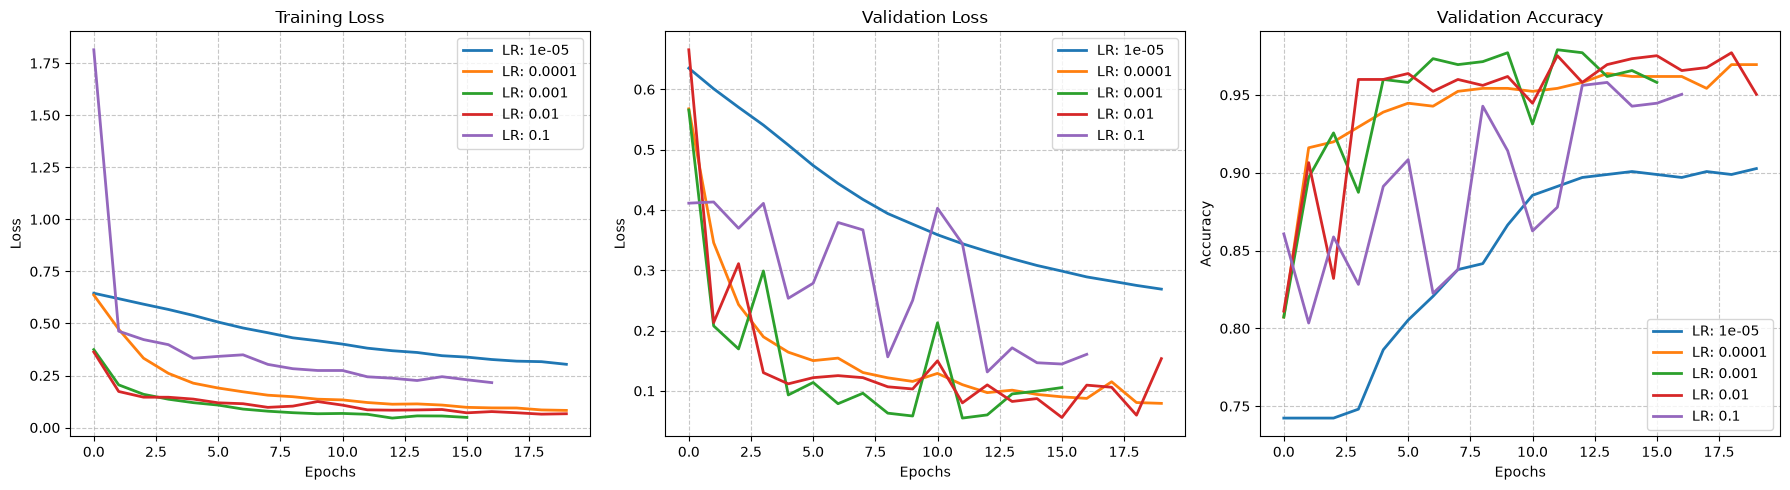

Best LR for B1: 0.001


In [11]:
def run_lr_sweep(lrs, train_loader, val_loader, device):
    results = {}
    for lr in lrs:
        print(f"Training B1 with LR: {lr}")
        model_b1 = B1_AlexNet().to(device)
        
        # Make sure your train_model function returns a dictionary 
        # containing 'train_loss', 'val_loss', and 'val_acc' lists
        history = train_model(model_b1, train_loader, val_loader, lr)
        results[lr] = history
        
    return results

# 3. Execution Pipeline
lrs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

# Run the sweep
b1_results = run_lr_sweep(lrs, train_loader, val_loader, device)

# Plot the 3-panel results
plot_sweep_results(
    results=b1_results, 
    label_prefix='LR', 
    save_filename='learning_rate_comparison.png'
)

# Extract best LR
best_lr_b1 = max(b1_results, key=lambda k: max(b1_results[k]['val_acc']))
print(f"Best LR for B1: {best_lr_b1}")

# BCG Like Architecture

In [31]:
class B2_VGG(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(1, 8, 3),
            ConvBlock(8, 8, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(8, 16, 3),
            ConvBlock(16, 16, 3),
            nn.MaxPool2d(2, 2),
            ConvBlock(16, 32, 3),
            ConvBlock(32, 32, 3),
            nn.MaxPool2d(2, 2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 1, bias=True)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

# B2 Hyperparameter Search

#### Early Stopping

In [32]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Early Stopping (Required by assignment specifications)
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

##### Training Function

In [39]:
def train_vgg_model(model, train_loader, val_loader, lr, device, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    
    # # Weight decay and gradient clipping kept for VGG stability
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    # scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    early_stopping = EarlyStopping(patience=4, min_delta=1e-4)
    
    # Now tracking train_loss alongside val metrics
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # --- Training Phase ---
        model.train()
        running_train_loss = 0.0
        
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            running_train_loss += loss.item() * inputs.size(0)
            
        # --- Validation Phase ---
        model.eval()
        running_val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        # --- Metrics Calculation ---
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        # scheduler.step(epoch_val_loss)
        early_stopping(epoch_val_loss)
        
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

In [40]:
def run_batch_size_sweep(batch_sizes, lr, device):
    results = {}
    for bs in batch_sizes:
        print(f"Training VGG with Batch Size: {bs} at LR: {lr}")
        train_loader_bs, val_loader_bs, _, _, _ = load_and_preprocess_data(batch_size=bs)
        
        model_b2 = B2_VGG().to(device)
        history = train_vgg_model(model_b2, train_loader_bs, val_loader_bs, lr, device)
        results[bs] = history
        
    return results

# 4. Modular Plotting Function (3 Panels)
def plot_sweep_results(results, save_filename='vgg_batch_size_comparison.png'):
    os.makedirs('images', exist_ok=True)
    # Expanded to a 1x3 grid to include Training Loss
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for bs, history in results.items():
        axes[0].plot(history['train_loss'], label=f'Batch: {bs}', linewidth=2)
        axes[1].plot(history['val_loss'], label=f'Batch: {bs}', linewidth=2)
        axes[2].plot(history['val_acc'], label=f'Batch: {bs}', linewidth=2)

    # Train Loss Plot
    axes[0].set_title('Training Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Val Loss Plot
    axes[1].set_title('Validation Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Val Accuracy Plot
    axes[2].set_title('Validation Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    output_path = os.path.join('images', save_filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

Training VGG with Batch Size: 16 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 15
Training VGG with Batch Size: 32 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 14
Training VGG with Batch Size: 64 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 14
Training VGG with Batch Size: 128 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 11
Training VGG with Batch Size: 256 at LR: 0.001
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 1

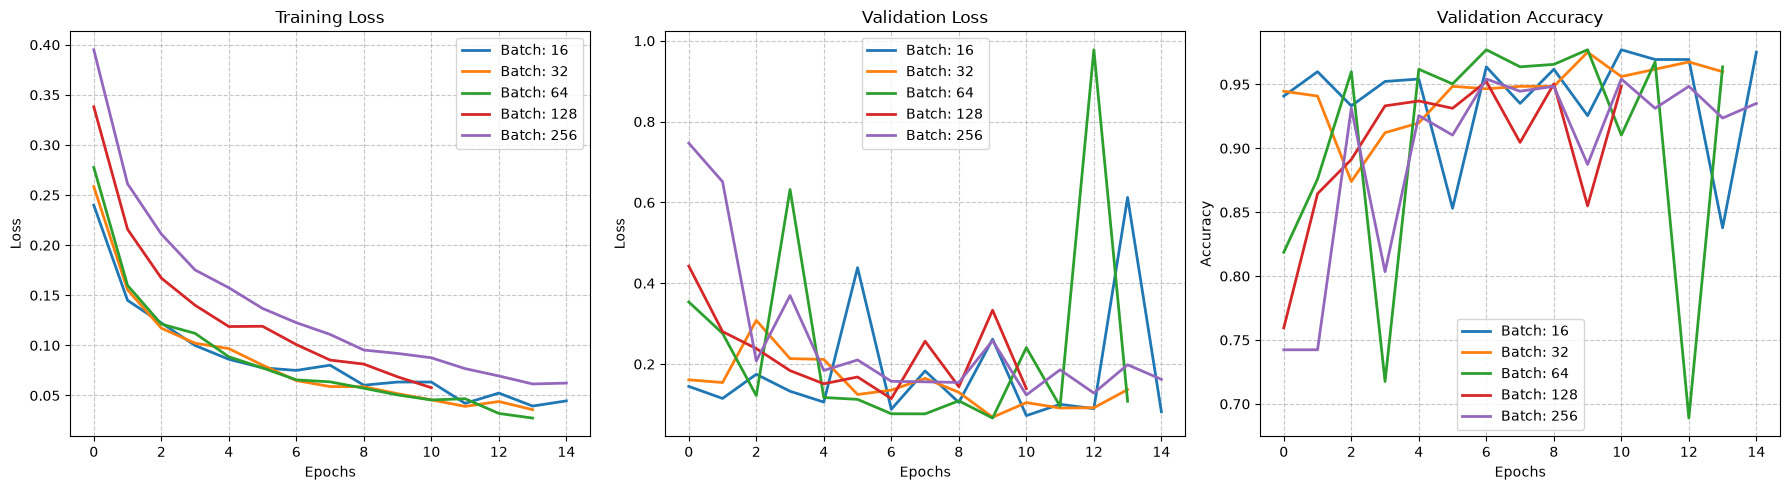

Best Batch Size for VGG: 16


In [41]:
# 5. Execution Pipeline
batch_sizes = [16, 32, 64, 128, 256]

# Note: The assignment specifies using the optimal learning rate found in B1 for this step.
# Make sure `best_lr_b1` is defined from your previous B1 code cell.
current_lr = best_lr_b1 if 'best_lr_b1' in locals() else 1e-4 

b2_results = run_batch_size_sweep(batch_sizes, current_lr, device)
plot_sweep_results(b2_results)

best_bs_b2 = max(b2_results, key=lambda k: max(b2_results[k]['val_acc']))
print(f"Best Batch Size for VGG: {best_bs_b2}")

# B3 - ResNet Like Architecture

In [44]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = ConvBlock(in_c, out_c, 3, stride=stride)
        # Note: BatchNorm and ReLU are inside ConvBlock
        self.conv2 = nn.Conv2d(out_c, out_c, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_c)
            )
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.conv1(x)
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out) # ReLU applied after residual addition

class B3_ResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.prep = nn.Sequential(
            ConvBlock(1, 16, 3),
            nn.MaxPool2d(2, 2)
        )
        self.layer1 = ResBlock(16, 16, stride=1)
        self.layer2 = ResBlock(16, 32, stride=2)
        self.layer3 = ResBlock(32, 64, stride=2)
        
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, 1, bias=True)

    def forward(self, x):
        x = self.prep(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

--- Training B3 ResNet (Plain Training) ---
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Epoch [1/20] - Val Loss: 0.1817 - Val Acc: 0.9294
Epoch [2/20] - Val Loss: 0.2747 - Val Acc: 0.8893
Epoch [3/20] - Val Loss: 0.1250 - Val Acc: 0.9542
Epoch [4/20] - Val Loss: 0.0732 - Val Acc: 0.9752
Epoch [5/20] - Val Loss: 0.3657 - Val Acc: 0.8683
Epoch [6/20] - Val Loss: 0.1078 - Val Acc: 0.9637
Epoch [7/20] - Val Loss: 0.1370 - Val Acc: 0.9466
Epoch [8/20] - Val Loss: 0.1168 - Val Acc: 0.9523
Epoch [9/20] - Val Loss: 0.1008 - Val Acc: 0.9637
Epoch [10/20] - Val Loss: 0.0745 - Val Acc: 0.9752
Epoch [11/20] - Val Loss: 0.1655 - Val Acc: 0.9408
Epoch [12/20] - Val Loss: 0.1031 - Val Acc: 0.9676
Epoch [13/20] - Val Loss: 0.1231 - Val Acc: 0.9561
Epoch [14/20] - Val Loss: 0.1086 - Val Acc: 0.9676
Epoch [15/20] - Val Loss: 0.0973 - Val Acc: 0.9733
Epoch [16/20] - Val Loss: 0.0703 - Val Acc: 0.9790
Epoch [17/20] - Val Loss: 0.1013

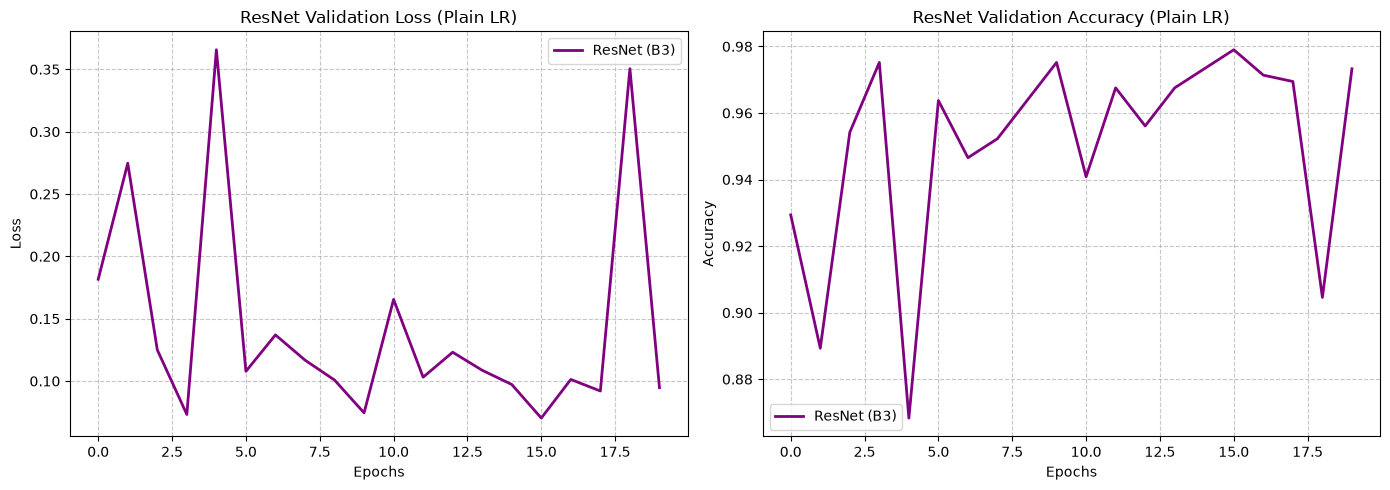


--- Final Test Set Evaluation & Metrics ---

Model: B1_AlexNet
  Accuracy    : 0.6250
  Precision   : 0.6250
  Sensitivity : 1.0000
  Specificity : 0.0000

--- Architecture Summary for B1_AlexNet ---

Model: B2_VGG
  Accuracy    : 0.8157
  Precision   : 0.7812
  Sensitivity : 0.9795
  Specificity : 0.5427

--- Architecture Summary for B2_VGG ---

Model: B3_ResNet
  Accuracy    : 0.8734
  Precision   : 0.8463
  Sensitivity : 0.9744
  Specificity : 0.7051

--- Architecture Summary for B3_ResNet ---


In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchinfo import summary
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# --- 1. Modular Training Function (Tracks Train Loss & Uses Early Stopping) ---
def train_model_standard(model, train_loader, val_loader, lr, device, epochs=20):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    # Reusing the EarlyStopping class defined in previous cells
    early_stopping = EarlyStopping(patience=4, min_delta=1e-4)
    
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_train_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * inputs.size(0)
            
        # Validation Phase
        model.eval()
        running_val_loss = 0.0
        correct = 0
        total = 0
        
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
                preds = (torch.sigmoid(outputs) > 0.5).float()
                correct += (preds == targets).sum().item()
                total += targets.size(0)
                
        # Calculate Epoch Metrics
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)
        
        early_stopping(epoch_val_loss)
        if early_stopping.early_stop:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
            
    return history

# --- 2. Modular Plotting Function (3 Panels) ---
def plot_model_history(history, model_name='Model', save_filename='model_history.png'):
    os.makedirs('images', exist_ok=True)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Training Loss Plot
    axes[0].plot(history['train_loss'], label=f'{model_name} Train', color='blue', linewidth=2)
    axes[0].set_title(f'{model_name} Training Loss')
    axes[0].set_xlabel('Epochs')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # Validation Loss Plot
    axes[1].plot(history['val_loss'], label=f'{model_name} Val', color='orange', linewidth=2)
    axes[1].set_title(f'{model_name} Validation Loss')
    axes[1].set_xlabel('Epochs')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.7)

    # Validation Accuracy Plot
    axes[2].plot(history['val_acc'], label=f'{model_name} Val', color='green', linewidth=2)
    axes[2].set_title(f'{model_name} Validation Accuracy')
    axes[2].set_xlabel('Epochs')
    axes[2].set_ylabel('Accuracy')
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    output_path = os.path.join('images', save_filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Plot saved to {output_path}")
    plt.show()

# --- 3. Modular Evaluation Function ---
def evaluate_model(model, loader, device):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.round(torch.sigmoid(outputs))
            
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'accuracy': acc,
        'precision': precision,
        'sensitivity': sensitivity,
        'specificity': specificity
    }

# --- 4. Execution Pipeline ---
print("--- Training B3 ResNet ---")
# Use the optimal batch size found in B2
train_loader_final, val_loader_final, test_loader_final, _, _ = load_and_preprocess_data(batch_size=best_bs_b2)

model_b3 = B3_ResNet().to(device)
# Use the optimal learning rate found in B1
b3_history = train_model_standard(model_b3, train_loader_final, val_loader_final, lr=best_lr_b1, device=device)

# Plot Training and Validation curves for ResNet
plot_model_history(b3_history, model_name='ResNet (B3)', save_filename='resnet_b3_history.png')

# --- 5. Final Comparison & Architecture Summaries ---
models = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

print("\n--- Final Test Set Evaluation & Metrics ---")
for name, model in models.items():
    metrics = evaluate_model(model, test_loader_final, device)
    print(f"\nModel: {name}")
    print(f"  Accuracy    : {metrics['accuracy']:.4f}")
    print(f"  Precision   : {metrics['precision']:.4f}")
    print(f"  Sensitivity : {metrics['sensitivity']:.4f}")
    print(f"  Specificity : {metrics['specificity']:.4f}")
    
    print(f"\n--- Architecture Summary for {name} ---")
    summary(model, input_size=(best_bs_b2, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "mult_adds"])

--- Training B3 ResNet ---
Keys inside the npz file: ['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']
Early stopping triggered at epoch 13
Plot saved to images/resnet_b3_history.png


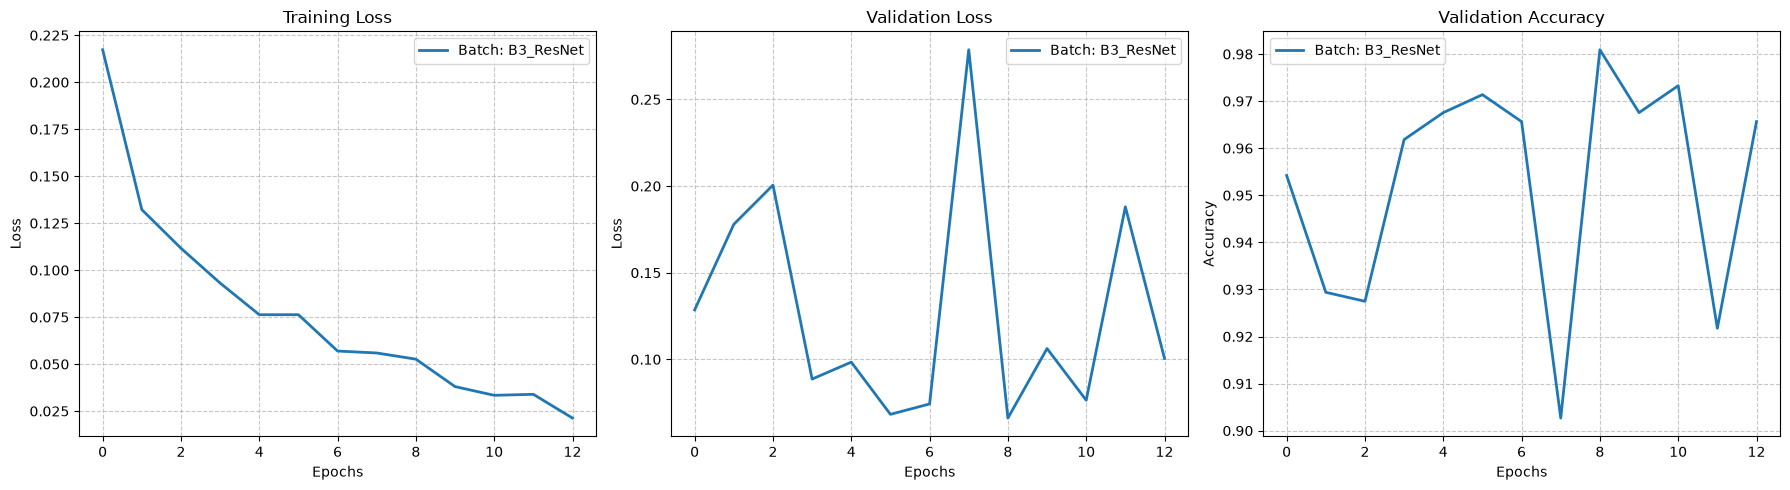


--- Final Test Set Evaluation & Metrics ---

Model: B1_AlexNet
  Accuracy             : 0.3750
  Classification Error : 0.6250
  Sensitivity          : 0.0000
  Specificity          : 1.0000

--- Architecture Summary for B1_AlexNet ---

Model: B2_VGG
  Accuracy             : 0.6250
  Classification Error : 0.3750
  Sensitivity          : 1.0000
  Specificity          : 0.0000

--- Architecture Summary for B2_VGG ---

Model: B3_ResNet
  Accuracy             : 0.8317
  Classification Error : 0.1683
  Sensitivity          : 0.9974
  Specificity          : 0.5556

--- Architecture Summary for B3_ResNet ---


In [47]:
import os
import numpy as np
import torch
from torchinfo import summary
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# --- 1. Train B3 ResNet using existing modular functions ---
print("--- Training B3 ResNet ---")
# Use the optimal batch size found in B2
train_loader_final, val_loader_final, test_loader_final, _, _ = load_and_preprocess_data(batch_size=best_bs_b2)

model_b3 = B3_ResNet().to(device)

# Reuse the existing train_model function (using best_lr_b1 as required)
b3_history = train_model(model_b3, train_loader_final, val_loader_final, lr=best_lr_b1)

# Package into a dictionary to perfectly match your existing plot_sweep_results function
b3_results_dict = {'B3_ResNet': b3_history}

# Reuse the existing plotting function
plot_sweep_results(b3_results_dict, save_filename='resnet_b3_history.png')


# --- 2. Final Evaluation Function ---
def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            # Apply sigmoid to raw logits to get probabilities, then round to 0 or 1
            preds = torch.round(torch.sigmoid(outputs))
            
            y_true.extend(targets.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    sensitivity = recall_score(y_true, y_pred, zero_division=0)
    
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    else:
        specificity = 0.0
        
    return {
        'accuracy': acc,
        'precision': precision,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'classification_error': 1 - acc
    }

# --- 3. Final Comparison & Architecture Summaries ---
model_b1 = B1_AlexNet().to(device)
model_b2 = B2_VGG().to(device)

models = {
    'B1_AlexNet': model_b1,
    'B2_VGG': model_b2,
    'B3_ResNet': model_b3
}

print("\n--- Final Test Set Evaluation & Metrics ---")
for name, model in models.items():
    metrics = evaluate_model(model, test_loader_final)
    print(f"\nModel: {name}")
    print(f"  Accuracy             : {metrics['accuracy']:.4f}")
    print(f"  Classification Error : {metrics['classification_error']:.4f}")
    print(f"  Sensitivity          : {metrics['sensitivity']:.4f}")
    print(f"  Specificity          : {metrics['specificity']:.4f}")
    
    print(f"\n--- Architecture Summary for {name} ---")
    # Generates FLOPs and Params required for the final comparison table
    summary(model, input_size=(best_bs_b2, 1, 64, 64), col_names=["input_size", "output_size", "num_params", "mult_adds"])

# Explainable AI

In [48]:
print("--- AlexNet (model_b1) Layers ---")
for idx, layer in enumerate(model_b1.features):
    print(f"{idx}: {type(layer)}")

print("\n--- VGG (model_b2) Layers ---")
for idx, layer in enumerate(model_b2.features):
    print(f"{idx}: {type(layer)}")

--- AlexNet (model_b1) Layers ---
0: <class '__main__.ConvBlock'>
1: <class 'torch.nn.modules.pooling.MaxPool2d'>
2: <class '__main__.ConvBlock'>
3: <class 'torch.nn.modules.pooling.MaxPool2d'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>

--- VGG (model_b2) Layers ---
0: <class '__main__.ConvBlock'>
1: <class '__main__.ConvBlock'>
2: <class 'torch.nn.modules.pooling.MaxPool2d'>
3: <class '__main__.ConvBlock'>
4: <class '__main__.ConvBlock'>
5: <class 'torch.nn.modules.pooling.MaxPool2d'>
6: <class '__main__.ConvBlock'>
7: <class '__main__.ConvBlock'>
8: <class 'torch.nn.modules.pooling.MaxPool2d'>
9: <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>


--- Generating Smooth Grad-CAM Visualizations ---


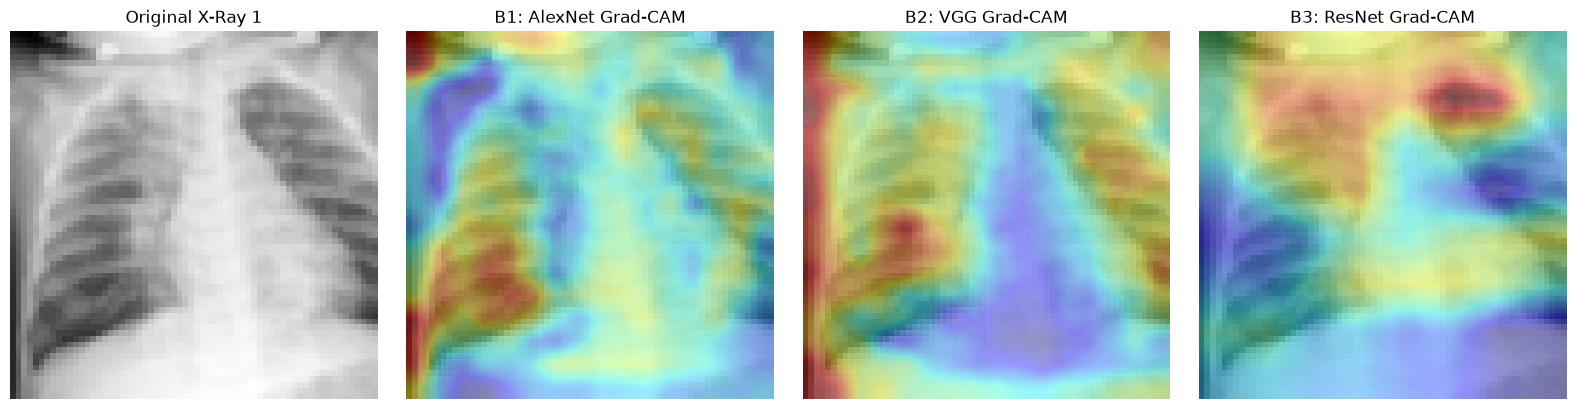

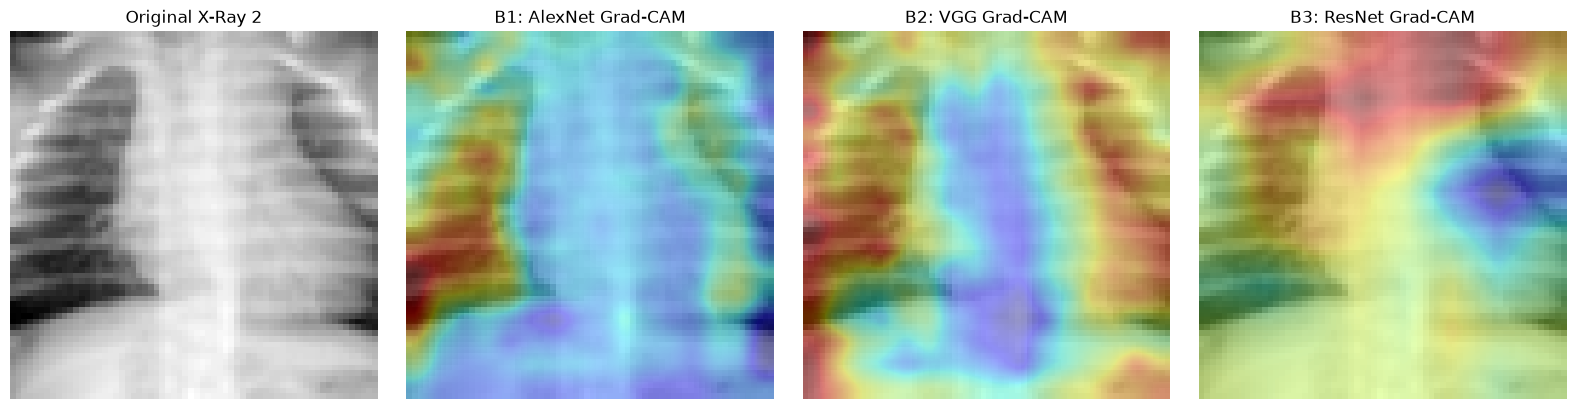

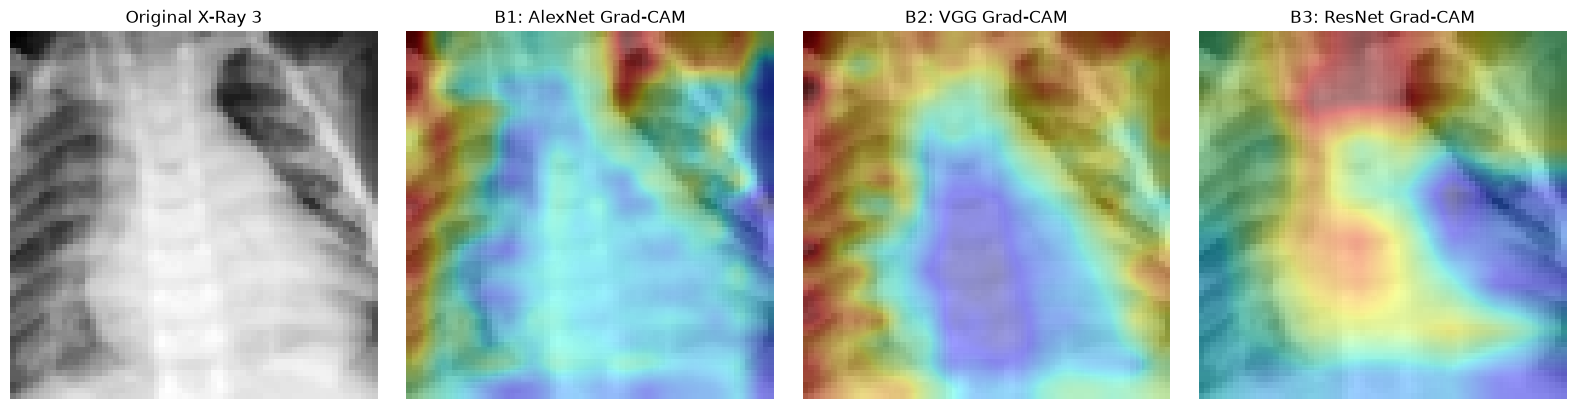

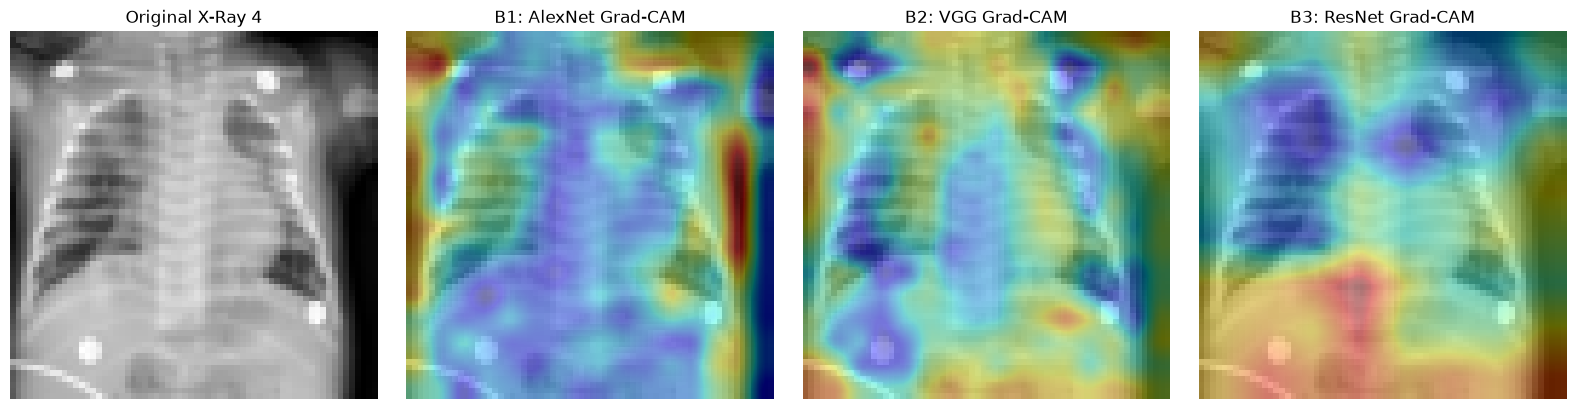

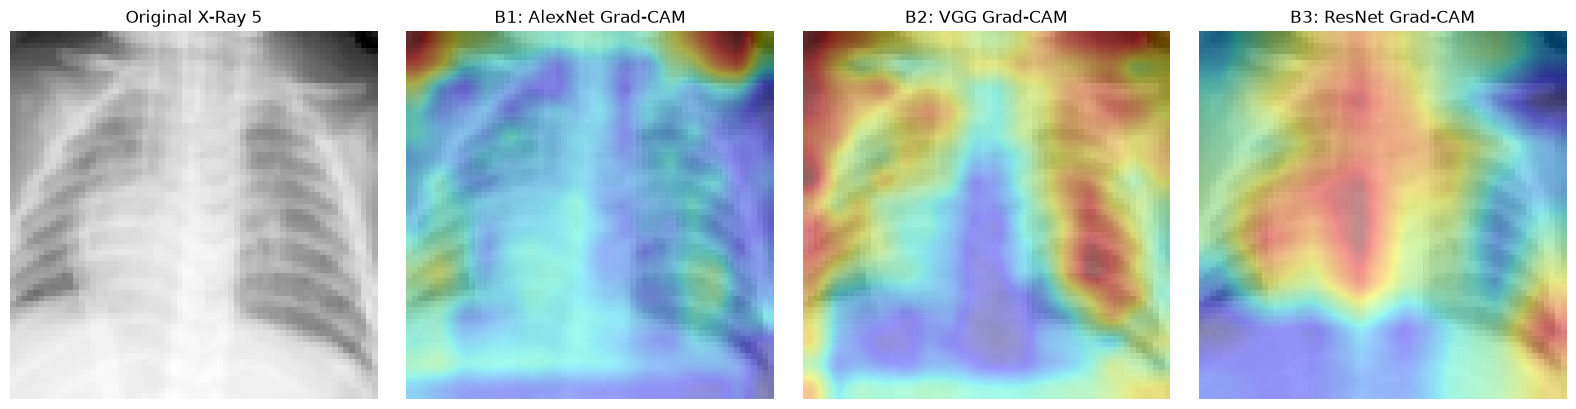

Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!
ROC Curve plot saved successfully to images/roc_curve_comparison.png


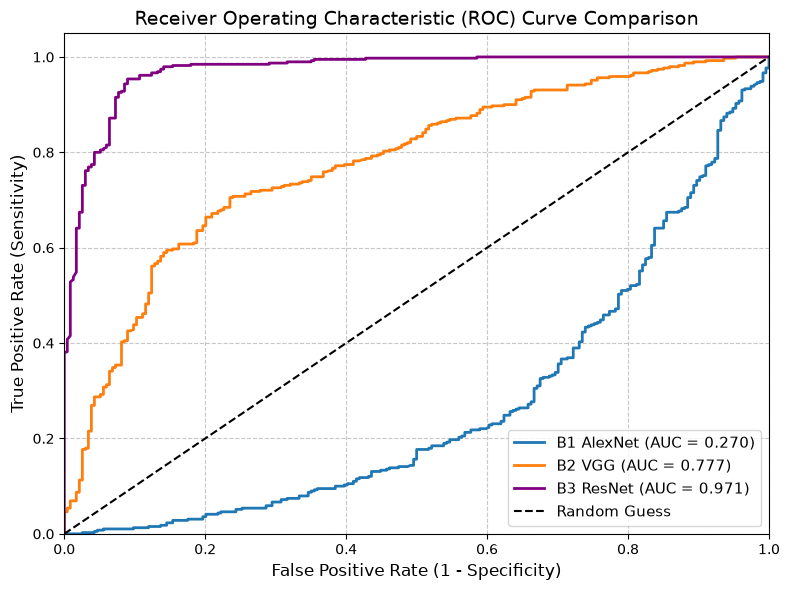

In [50]:
import os
import torch
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from captum.attr import LayerGradCam

# 1. Select 5 random pneumonia positive samples (target == 1)
pneumonia_indices = torch.where(y_test_t == 1)[0]
sample_indices = pneumonia_indices[torch.randperm(len(pneumonia_indices))[:5]]
sample_images = X_test_t[sample_indices].to(device)

# Ensure models are in evaluation mode
model_b1.eval()
model_b2.eval()
model_b3.eval()

# 2. Initialize Grad-CAM targeting the inner conv layer of the final ConvBlock / ResNet layer
# Based on your layer printouts:
# AlexNet last ConvBlock is at features[4]
# VGG last ConvBlock is at features[6]
# ResNet last layer is layer3.conv2 (or check if your ResNet uses standard blocks, we can target layer3)

# Helper to find the conv layer inside your custom ConvBlock if needed, 
# or directly access if it's named 'conv' or similar inside ConvBlock:
def get_conv_from_block(block):
    # Search for any Conv2d module inside the custom ConvBlock
    for m in block.modules():
        if isinstance(m, torch.nn.Conv2d):
            return m
    raise ValueError("No Conv2d found in this block")

cam_b1 = LayerGradCam(model_b1, get_conv_from_block(model_b1.features[4]))
cam_b2 = LayerGradCam(model_b2, get_conv_from_block(model_b2.features[6]))
# cam_b3 = LayerGradCam(model_b3, model_b3.layer3.conv2) # Adjust to model_b3.layer4[1].conv2 if ResNet-18/50 style
cam_3 = LayerGradCam(model_b3, model_b3.layer3)

os.makedirs('images/gradcam', exist_ok=True)

print("--- Generating Smooth Grad-CAM Visualizations ---")
for i in range(5):
    img = sample_images[i:i+1] # Shape: (1, 1, H, W)
    
    # Generate attributions
    attr_b1 = cam_b1.attribute(img, target=None)
    attr_b2 = cam_b2.attribute(img, target=None)
    attr_b3 = cam_b3.attribute(img, target=None)
    
    # Upsample attributions smoothly to original image dimensions using torch.nn.functional.interpolate
    target_size = img.shape[2:] # (H, W)
    attr_b1_up = F.interpolate(attr_b1, size=target_size, mode='bilinear', align_corners=False)
    attr_b2_up = F.interpolate(attr_b2, size=target_size, mode='bilinear', align_corners=False)
    attr_b3_up = F.interpolate(attr_b3, size=target_size, mode='bilinear', align_corners=False)
    
    orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    # Original Image
    axes[0].imshow(orig_img_np, cmap='gray')
    axes[0].set_title(f"Original X-Ray {i+1}")
    axes[0].axis('off')
    
    # Helper to plot smooth heatmap overlay
    def plot_smooth_heatmap(ax, bg_img, attr_tensor, title):
        ax.imshow(bg_img, cmap='gray')
        hm = attr_tensor.squeeze().detach().cpu().numpy()
        if hm.max() > hm.min():
            hm = (hm - hm.min()) / (hm.max() - hm.min()) # Normalize between 0 and 1
        ax.imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
        ax.set_title(title)
        ax.axis('off')

    plot_smooth_heatmap(axes[1], orig_img_np, attr_b1_up, "B1: AlexNet Grad-CAM")
    plot_smooth_heatmap(axes[2], orig_img_np, attr_b2_up, "B2: VGG Grad-CAM")
    plot_smooth_heatmap(axes[3], orig_img_np, attr_b3_up, "B3: ResNet Grad-CAM")
    
    plt.tight_layout()
    save_path = os.path.join('images/gradcam', f'sample_{i+1}_gradcam.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

print("Smooth Grad-CAM images successfully generated and saved to 'images/gradcam/'!")


# --- 3. ROC Curve Generation ---
def get_probabilities(model, loader):
    model.eval()
    y_true, y_probs = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.sigmoid(outputs)
            y_true.extend(targets.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())
    return np.array(y_true), np.array(y_probs)

y_true_b1, y_prob_b1 = get_probabilities(model_b1, test_loader_final)
y_true_b2, y_prob_b2 = get_probabilities(model_b2, test_loader_final)
y_true_b3, y_prob_b3 = get_probabilities(model_b3, test_loader_final)

fpr_b1, tpr_b1, _ = roc_curve(y_true_b1, y_prob_b1)
roc_auc_b1 = auc(fpr_b1, tpr_b1)

fpr_b2, tpr_b2, _ = roc_curve(y_true_b2, y_prob_b2)
roc_auc_b2 = auc(fpr_b2, tpr_b2)

fpr_b3, tpr_b3, _ = roc_curve(y_true_b3, y_prob_b3)
roc_auc_b3 = auc(fpr_b3, tpr_b3)

plt.figure(figsize=(8, 6))
plt.plot(fpr_b1, tpr_b1, label=f'B1 AlexNet (AUC = {roc_auc_b1:.3f})', linewidth=2)
plt.plot(fpr_b2, tpr_b2, label=f'B2 VGG (AUC = {roc_auc_b2:.3f})', linewidth=2)
plt.plot(fpr_b3, tpr_b3, label=f'B3 ResNet (AUC = {roc_auc_b3:.3f})', linewidth=2, color='purple')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
roc_output_path = os.path.join('images', 'roc_curve_comparison.png')
plt.savefig(roc_output_path, dpi=300, bbox_inches='tight')
print(f"ROC Curve plot saved successfully to {roc_output_path}")
plt.show()

## Error Analysis using Grad CAM

Total False Negatives found: 3
Total False Positives found: 70

--- Generating Grad-CAM for False_Negative (3 samples) ---


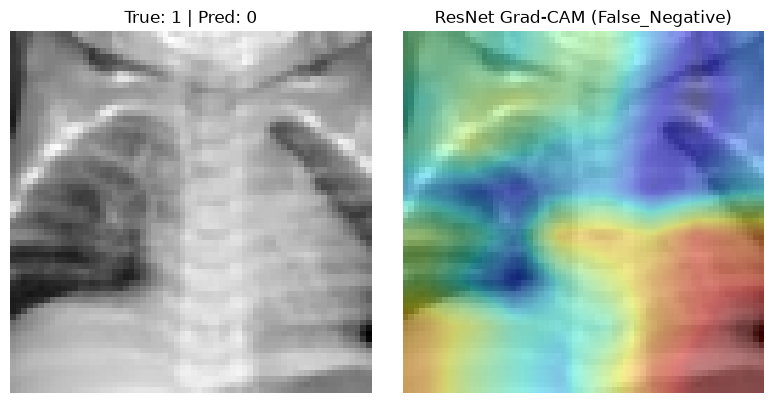

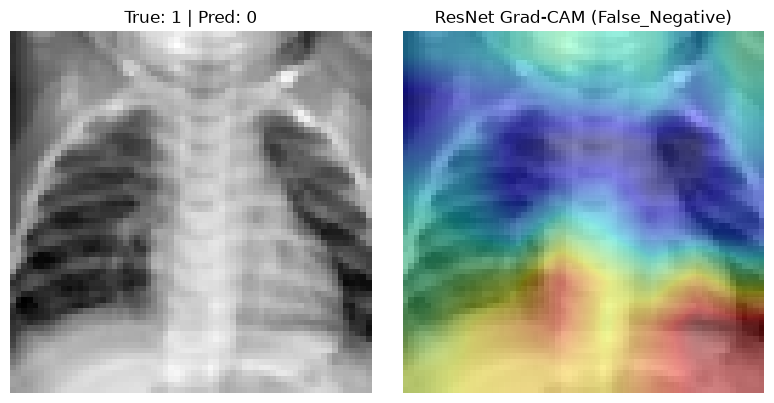

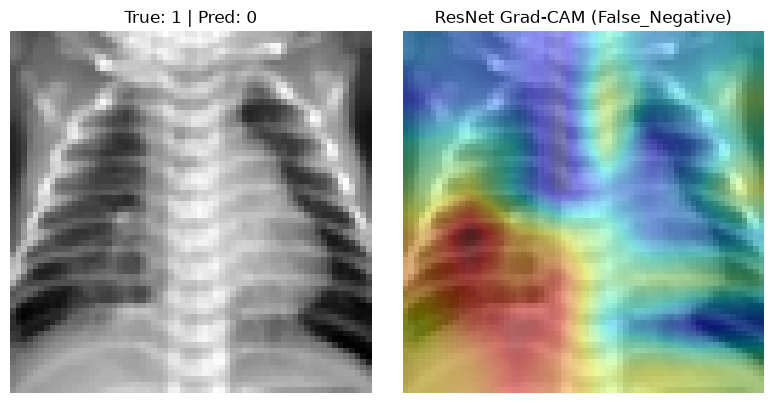


--- Generating Grad-CAM for False_Positive (5 samples) ---


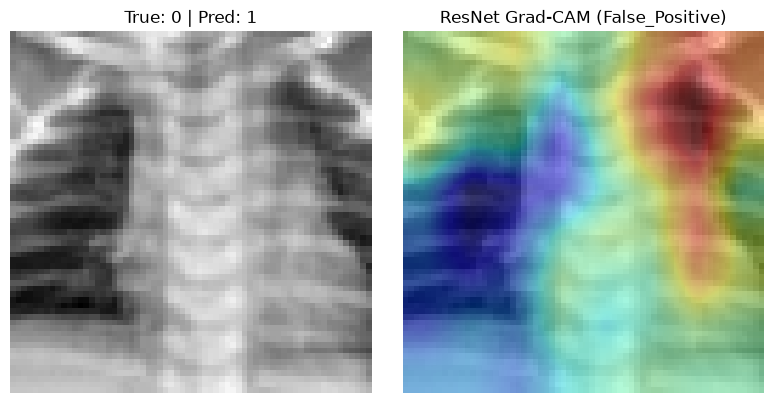

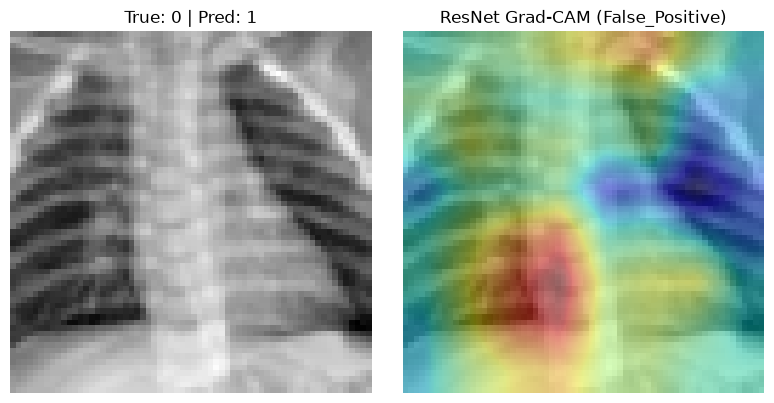

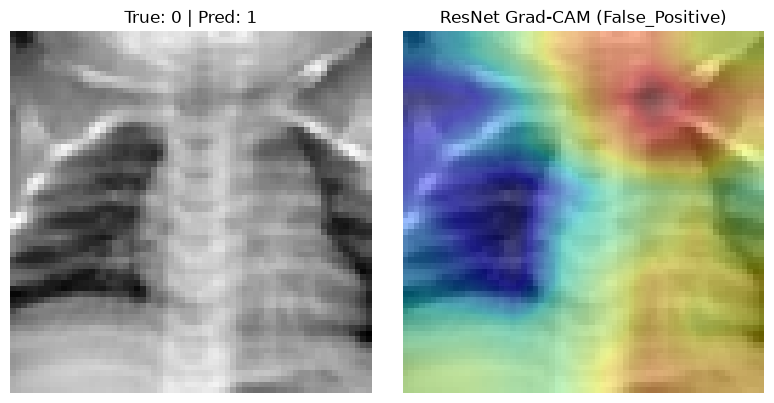

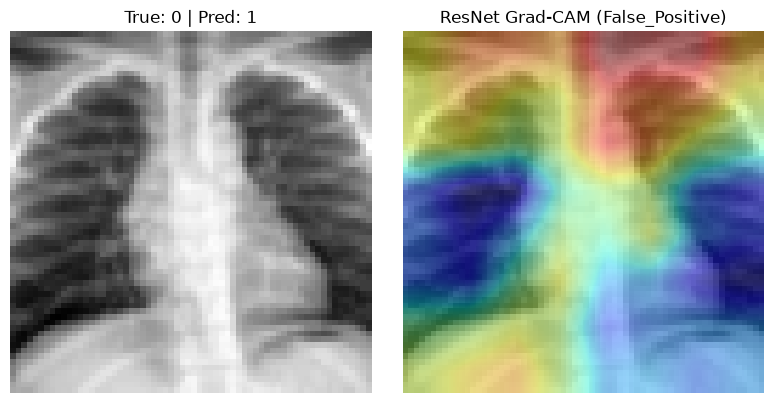

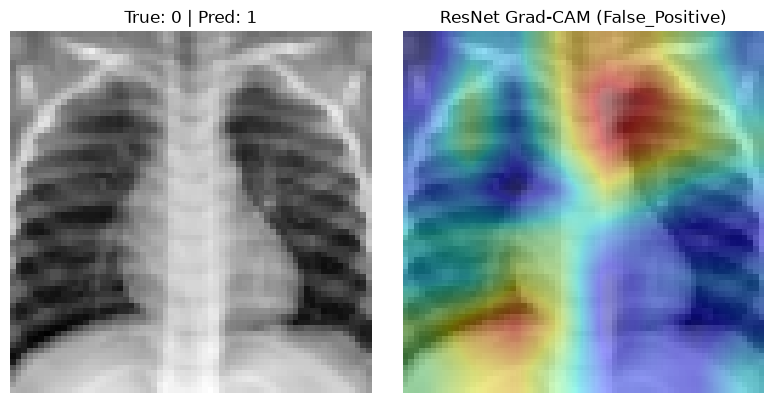

In [28]:
import os
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from captum.attr import LayerGradCam

# Ensure output directory exists
os.makedirs('images/error_analysis', exist_ok=True)

# 1. Get predictions for the entire test set using our best model (ResNet - B3)
model_b3.eval()
all_preds, all_targets, all_images = [], [], []

with torch.no_grad():
    for inputs, targets in test_loader_final:
        inputs = inputs.to(device)
        outputs = model_b3(inputs)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())
        all_images.append(inputs.cpu())

all_preds = np.array(all_preds).squeeze()
all_targets = np.array(all_targets).squeeze()
all_images = torch.cat(all_images, dim=0)

# 2. Identify False Negatives and False Positives indices
fn_indices = np.where((all_preds == 0) & (all_targets == 1))[0] # Missed Pneumonia
fp_indices = np.where((all_preds == 1) & (all_targets == 0))[0] # False Alarm (Normal flagged as Pneumonia)

print(f"Total False Negatives found: {len(fn_indices)}")
print(f"Total False Positives found: {len(fp_indices)}")

# 3. Initialize Grad-CAM for ResNet (model_b3)
cam_b3 = LayerGradCam(model_b3, model_b3.layer3.conv2)

def generate_error_gradcam(indices, error_type_name):
    if len(indices) == 0:
        print(f"No {error_type_name} samples found to analyze.")
        return
    
    # Pick up to 5 samples
    selected_indices = indices[:5]
    error_images = all_images[selected_indices].to(device)
    
    print(f"\n--- Generating Grad-CAM for {error_type_name} ({len(selected_indices)} samples) ---")
    
    for i, idx in enumerate(selected_indices):
        img = error_images[i:i+1] # Shape: (1, 1, H, W)
        
        # Generate attributions
        attr = cam_b3.attribute(img, target=None)
        
        # Upsample smoothly using bilinear interpolation
        attr_up = F.interpolate(attr, size=img.shape[2:], mode='bilinear', align_corners=False)
        
        orig_img_np = img.squeeze(0).cpu().permute(1, 2, 0).numpy().squeeze()
        hm = attr_up.squeeze().detach().cpu().numpy()
        
        if hm.max() > hm.min():
            hm = (hm - hm.min()) / (hm.max() - hm.min())
            
        # Plotting side-by-side: Original vs Grad-CAM Overlay
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        
        # Original Image
        axes[0].imshow(orig_img_np, cmap='gray')
        axes[0].set_title(f"True: {int(all_targets[idx])} | Pred: {int(all_preds[idx])}")
        axes[0].axis('off')
        
        # Grad-CAM Heatmap Overlay
        axes[1].imshow(orig_img_np, cmap='gray')
        axes[1].imshow(hm, cmap='jet', alpha=0.4, interpolation='bilinear')
        axes[1].set_title(f"ResNet Grad-CAM ({error_type_name})")
        axes[1].axis('off')
        
        plt.tight_layout()
        save_path = os.path.join('images/error_analysis', f'{error_type_name}_sample_{i+1}.png')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.show()

# Run error analysis generation for both categories
generate_error_gradcam(fn_indices, "False_Negative")
generate_error_gradcam(fp_indices, "False_Positive")